In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Препроцессирование категориальных фичей, Feature engineering, разметка таргета и агрегация в единый датасет

Загрузим и объединим листы в один датафрейм для каждого файла, а также дропнем дубликаты

In [2]:
teacher_sheets = pd.read_excel('data/Педагоги.xlsx', sheet_name=None)
df_teacher_list = []
for year, sheet in teacher_sheets.items():
  sheet['year'] = int(year)
  df_teacher_list.append(sheet)

df_teachers = pd.concat(df_teacher_list, ignore_index=True).drop_duplicates()

education_sheets = pd.read_excel('data/Образование.xlsx', sheet_name=None)
df_edu_list = []
for year, sheet in education_sheets.items():
  sheet['year'] = int(year)
  df_edu_list.append(sheet)
df_education = pd.concat(df_edu_list, ignore_index=True).drop_duplicates()


pk_pp_sheets = pd.read_excel('data/ПК-ПП.xlsx', sheet_name=None)
df_pk_list = []
for year, sheet in pk_pp_sheets.items():
  sheet['year'] = int(year)
  df_pk_list.append(sheet)
df_pk_pp = pd.concat(df_pk_list, ignore_index=True).drop_duplicates()


df_schools = pd.read_excel('data/Школы.xlsx').drop_duplicates()

Для удобства переведем называние фичей в инглиш

In [3]:
df_teachers.rename(columns={
    'id': 'teacher_id', # ключ
    'ID образовательной организации': 'school_num', # ключ
    'Основная должность': 'main_position',
    'Направление деятельности': 'speciality',
    'Пол': 'sex',
    'Возраст': 'age',
    'Ученая степень': 'academic_degree',
    'Квалификационная категория (педагогического работника)': 'category_qual',
    'Дата присвоения квалификационной категории': 'category_date',
    'Срок действия квалификационной категории': 'category_due',
    'Общий стаж работы': 'experience_age_all',
    'Стаж педагогической работы': 'experience_age_pedagogic',
    'Предмет': 'subject',
    'Параллель': 'parallell',
    'Имеет классное руководство': 'class_manager',
}, inplace=True)

df_education.rename(columns={
    'id': 'teacher_id', # ключ
    'Краткое наименование образовательной организации': 'school_num',
    'Тип образования': 'type_education',
    'Наименование учебного заведения': 'edu_org_name',
    'Дата окончания': 'date_pass',
    'Специализация': 'specialization_edu',
    'Квалификация': 'qualification'
}, inplace=True)

df_pk_pp.rename(columns={
    'id': 'teacher_id', # ключ
    'Наименование программы': 'name_prog',
    'Программа профессиональной переподготовки(ПП)/повышения квалификации(ПК)': 'type_prog',
    'Количество часов': 'hours_tot',
    'Дата получения документа/освоения программы': 'date_done'
}, inplace=True)

df_schools.rename(columns={
    'Школа': 'school_num', # ключ
    'Округ': 'district',
    'Кол-во зданий': 'buildings_num',
    'Общая численность контингента': 'students_num',
}, inplace=True)

In [4]:
display(df_teachers.head())
print("-" * 200)
print("-" * 200)
display(df_education.head())
print("-" * 200)
print("-" * 200)
display(df_pk_pp.head())
print("-" * 200)
print("-" * 200)
display(df_schools.head())

,teacher_id,school_num,main_position,speciality,sex,age,academic_degree,category_qual,category_date,category_due,experience_age_all,experience_age_pedagogic,subject,parallell,class_manager,year
0,f583c34a49,478,Педагог дополнительного образования,NaN,Женский,35,NaN,NaN,NaN,NaN,12,1,Иностранный язык (английский),2,Нет,2022
1,f583c34a49,478,Педагог дополнительного образования,NaN,Женский,35,NaN,NaN,NaN,NaN,12,1,Иностранный язык (английский),6,Нет,2022
2,f583c34a49,478,Педагог дополнительного образования,NaN,Женский,35,NaN,NaN,NaN,NaN,12,1,Практикум,6,Нет,2022
3,f583c34a49,478,Педагог дополнительного образования,NaN,Женский,35,NaN,NaN,NaN,NaN,12,1,Иностранный язык (английский),9,Нет,2022
4,08ff701e26,523,Учитель,NaN,Женский,54,NaN,NaN,NaN,NaN,29,24,Физика,7,Нет,2022


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


,teacher_id,type_education,edu_org_name,date_pass,specialization_edu,qualification,year
0,f583c34a49,"Высшее образование - специалитет, магистратура","ФГОУ ВПО ""Государственный технологический унив...",2006.0,Теория и методика преподавания иностранных язы...,"Лингвист, преподаватель",2022
1,08ff701e26,Высшее образование,Бийский государственный педагогический институт,1989.0,Физика,учитель физики и математики,2022
2,b813df019b,Высшее образование,МОПИ им. Н. К. Крупской,1993.0,Математика,Учитель математики,2022
3,b813df019b,Дополнительное профессиональное образование,-,2016.0,Педагогика,NaN,2022
5,b813df019b,Дополнительное профессиональное образование,-,2016.0,NaN,NaN,2022


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


,teacher_id,name_prog,type_prog,hours_tot,date_done,year
0,18ac5986cd,Методические подходы в подготовке к государств...,ПК,16,2022,2022
1,18ac5986cd,Организация образовательного процесса в услови...,ПК,22,2022,2022
2,18ac5986cd,Подготовка организаторов пунктов проведения эк...,ПК,16,2022,2022
3,9b13af5810,Подготовка организаторов пунктов проведения эк...,ПК,16,2022,2022
4,1be672d40b,Инструменты объективного оценивания уровня дос...,ПК,18,2022,2022


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


,school_num,district,buildings_num,students_num
0,325,Инновационный округ,6,1294
1,397,Инновационный округ,3,842
2,192,Северный округ,13,4505
3,385,Западный округ,12,3617
4,269,Восточный округ,15,4262


In [5]:
display(df_teachers.info())
print("-" * 200)
print("-" * 200)
display(df_education.info())
print("-" * 200)
print("-" * 200)
display(df_pk_pp.info())
print("-" * 200)
print("-" * 200)
display(df_schools.info())

<class 'pandas.DataFrame'>
Index: 373042 entries, 0 to 428139
Data columns (total 16 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   teacher_id                373042 non-null  str    
 1   school_num                373042 non-null  int64  
 2   main_position             373042 non-null  str    
 3   speciality                244252 non-null  str    
 4   sex                       373042 non-null  str    
 5   age                       373042 non-null  int64  
 6   academic_degree           7578 non-null    str    
 7   category_qual             295457 non-null  str    
 8   category_date             295404 non-null  float64
 9   category_due              288294 non-null  float64
 10  experience_age_all        373042 non-null  int64  
 11  experience_age_pedagogic  373042 non-null  int64  
 12  subject                   373042 non-null  str    
 13  parallell                 373042 non-null  int64  
 14  clas

None

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
<class 'pandas.DataFrame'>
Index: 234370 entries, 0 to 302718
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   teacher_id          234370 non-null  str    
 1   type_education      234370 non-null  str    
 2   edu_org_name        234300 non-null  str    
 3   date_pass           233721 non-null  float64
 4   specialization_edu  113687 non-null  str    
 5   qualification       79351 non-null   str    
 6   year                234370 non-null  int64  
dtypes: float64(1), int64(1), str(5)
memory usage: 14.

None

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
<class 'pandas.DataFrame'>
Index: 65721 entries, 0 to 65732
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   teacher_id  65721 non-null  str  
 1   name_prog   65721 non-null  str  
 2   type_prog   65721 non-null  str  
 3   hours_tot   65721 non-null  int64
 4   date_done   65721 non-null  int64
 5   year        65721 non-null  int64
dtypes: int64(3), str(3)
memory usage: 3.5 MB


None

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   school_num     266 non-null    int64
 1   district       266 non-null    str  
 2   buildings_num  266 non-null    int64
 3   students_num   266 non-null    int64
dtypes: int64(3), str(1)
memory usage: 8.4 KB


None

Выделение фичей, первчиная обработка данных, кодирование признаков

In [6]:
# функция для вывода уникальных значений и их коливества
def info_about_feacher_values(df, col):
    print(f"=== {col} ({df[col].nunique()} уник.) ===")
    unique_vals = df[col].dropna().unique()
    print(", ".join(map(str, unique_vals)))
    print("-" * 200)

In [7]:
# функция для вывода графиков распределения фичей
warnings.filterwarnings('ignore', category=FutureWarning)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 9

def plot_dataset_cleaning_grid(df_before, df_after, columns, top_n=8):
    n_cols = len(columns)
    fig, axes = plt.subplots(2, n_cols, figsize=(5.5 * n_cols, 9), squeeze=False)

    for idx, col in enumerate(columns):
        ax_top = axes[0, idx]
        s_before = df_before[col].fillna('nan').astype(str)
        counts_before = s_before.value_counts().head(top_n)

        sns.barplot(
            x=counts_before.values,
            y=counts_before.index,
            hue=counts_before.index,
            legend=False,
            ax=ax_top,
            palette='crest'
        )
        ax_top.set_title(
            f'до: {col}\n(топ-{min(top_n, len(counts_before))} из {df_before[col].nunique()} уник.)',
            fontsize=11, fontweight='bold', pad=8
        )
        ax_top.set_xlabel('количество записей', fontsize=9)
        ax_top.set_ylabel('')

        for p in ax_top.patches:
            w = p.get_width()
            if w > 0:
                ax_top.annotate(
                    f'{int(w):,}',
                    (w, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center', xytext=(3, 0),
                    textcoords='offset points', fontsize=8
                )
        ax_bottom = axes[1, idx]
        s_after = df_after[col].fillna('nan').astype(str)
        counts_after = s_after.value_counts().head(top_n)

        sns.barplot(
            x=counts_after.values,
            y=counts_after.index,
            hue=counts_after.index,
            legend=False,
            ax=ax_bottom,
            palette='viridis'
        )
        ax_bottom.set_title(
            f'после: {col}\n(всего {df_after[col].nunique()} групп)',
            fontsize=11, fontweight='bold', pad=8
        )
        ax_bottom.set_xlabel('количество записей', fontsize=9)
        ax_bottom.set_ylabel('')

        for p in ax_bottom.patches:
            w = p.get_width()
            if w > 0:
                ax_bottom.annotate(
                    f'{int(w):,}',
                    (w, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center', xytext=(3, 0),
                    textcoords='offset points', fontsize=8
                )

    plt.tight_layout()
    plt.show()

Датасет учителей

До обработки:

In [8]:
teachers_catlist = ['main_position', 'speciality', 'sex', 'academic_degree', 'category_qual', 'subject', 'class_manager']

for col in teachers_catlist:
    info_about_feacher_values(df_teachers, col)

=== main_position (133 уник.) ===
Педагог дополнительного образования, Учитель, учитель, Учитель-логопед, Воспитатель, Преподаватель-организатор основ безопасности жизнедеятельности, Ведущий экономист, Музыкальный руководитель, Педагог-организатор, Учитель-дефектолог, Социальный педагог, Учитель биологии, Педагог-психолог, Заместитель директора, Учитель математики, Специалист по охране труда, Учитель физики, Тьютор, УЧИТЕЛЬ, Концертмейстер, Инструктор по физической культуре, Учитель китайского языка, Старший воспитатель, Старший вожатый, Системный администратор информационно-коммуникационных систем, Ведущий инженер, Педагог-библиотекарь, Методист, Учитель, 4 квалификационный уровень, Заведующий библиотекой, Учитель начальных классов, Старший специалист по сетевому администрированию, Заместитель директора по учебно-воспитательной работе, Специалист по связям с общественностью, Администратор, Ведущий специалист по сетевому администрированию, Воспитатель (ГПиУ), Учитель русского языка, Уч

In [9]:
df_teachers_raw = df_teachers.copy()

Здесь приводим текстовые поля к нижнему регистру и вычищаем пустые значенияи и сворачиваем их регулярками в более крупные группы

Для должностей выделяем руководящие позиции, предметников и вспомогательный персонал. Из должностей сразу вытаскиваем бинарный флаг is_main_teacher он равен 1, если человек реально работает учителем, и 0, если это завуч или методист с парой уроков. Это фича нужна потому что у совместителей маленькая нагрузка и модель без этой фичи будет путать их с увольняющимися учителями

Квалификационную категорию переводим в числа от 0 до 3, так как здесь строгий порядок высшая это 3, первая 2, вторая 1, а если пусто то ставим 0 потому что категории просто нет. Пол и классное руководство переводим в 1 и 0. Предметы собираем в 8 основных групп

Также вводим новую фичу is_high_school_core гле ставим 1 тем учителям кто ведет профильные экзаменационные предметы в выпускных классах. У них постоянный стресс из за экзов, куча внеурочных проверок и самый высокий риск выгорания. Из опыта знаю, что учителя часто доводят свой класс до экзаменов а после переводятся или покидают сферу образорвания, все также из-за высокой нагрузки и результатов статистки сдающих

In [10]:
for col in teachers_catlist: # приводим к единому виду
    df_teachers[col] = (df_teachers[col].astype(str).str.lower().str.strip().replace({'nan': np.nan, 'none': np.nan, '': np.nan, '-': np.nan}))



# academic_degree
def clean_academic_degree(val):
    if pd.isna(val):
        return 'нет степени'
    val = str(val).lower()
    if 'доктор' in val:
        return 'доктор наук'
    if 'кандидат' in val:
        return 'кандидат наук'
    return 'нет степени'

df_teachers['academic_degree'] = df_teachers['academic_degree'].apply(clean_academic_degree)
# кодируем фичу
df_teachers['academic_degree'] = df_teachers['academic_degree'].apply(lambda x: 1 if x in ['кандидат наук', 'доктор наук'] else 0)



# category_qual
def clean_category_qual(val): # закодируем эту фичу, тк тут строго порядковая шкала
    if pd.isna(val):
        return 0 # наны запонялем нулем, потому что учителя просто могут не иметь категории
    if 'высшая' in val:
        return 3
    if 'первая' in val:
        return 2
    if 'вторая' in val:
        return 1
    return 0

df_teachers['category_qual'] = df_teachers['category_qual'].apply(clean_category_qual)



# main_position
# создаем новую фичу: работает ли учителем по основной должности 1 или 0
df_teachers['is_main_teacher'] = np.where(df_teachers['main_position'].astype(str).str.lower().str.contains(r'учител|преподават', regex=True),1,0)

def clean_position(val):
    if pd.isna(val):
        return 'прочее'
    s = str(val).lower()

    # руководящий состав
    if any(k in s for k in ['директор', 'руководител', 'заведующ', 'начальник', 'декан']):
        if 'зам' in s or 'первый' in s:
            return 'заместитель руководителя'
        return 'руководитель'

    # педагоги со специальной квалификацией
    if 'логопед' in s:
        return 'учитель-логопед'
    if 'дефектолог' in s or 'олигофренопедагог' in s:
        return 'учитель-дефектолог'
    if 'психолог' in s:
        return 'педагог-психолог'
    if 'начальных классов' in s:
        return 'учитель начальных классов'
    if 'дополнительного образования' in s or 'допонительного' in s:
        return 'педагог дополнительного образования'
    if 'воспитател' in s:
        return 'воспитатель'
    if 'социальн' in s:
        return 'социальный педагог'
    if 'педагог-организатор' in s or 'педагог организатор' in s or 'вожат' in s:
        return 'педагог-организатор/вожатый'
    if 'тьютор' in s or 'ассистент' in s:
        return 'тьютор/ассистент'
    if 'методист' in s:
        return 'методист'
    if 'библиотек' in s:
        return 'библиотекарь'

    # учителя предметники и обж
    if 'учитель' in s or 'преподаватель' in s:
        if 'обж' in s or 'безопасности жизнедеятельности' in s:
            return 'преподаватель организатор обж'
        return 'учитель предметник'

    # it, инженерия, безопасность, офис
    if any(k in s for k in ['системный администратор', 'сетевому администрированию', 'баз данных']):
        return 'it специалист'
    if any(k in s for k in ['инженер', 'техник', 'наладчик']):
        return 'инженерно-технический персонал'
    if any(k in s for k in ['экономист', 'финанс', 'контрактный']):
        return 'экономист/бухгалтер'
    if any(k in s for k in ['кадр', 'делопроизводитель', 'документовед', 'секретар']):
        return 'делопроизводство и кадры'
    if any(k in s for k in ['безопасности', 'охране труда', 'гражданской обороне']):
        return 'специалист по безопасности и от'
    if any(k in s for k in ['музык', 'концертмейстер', 'звукооператор', 'режиссер']):
        return 'музыкальный/творческий работник'
    if 'инструктор по' in s or 'тренер' in s:
        return 'инструктор/тренер'
    if any(k in s for k in ['специалист', 'администратор', 'диспетчер']):
        return 'административный специалист'
    if any(k in s for k in ['рабочий', 'мастер', 'лаборант']):
        return 'учебно вспомогательный персонал'

    return 'прочее'

df_teachers['main_position'] = df_teachers['main_position'].apply(clean_position)



# speciality
def clean_speciality(val):
    if pd.isna(val):
        return np.nan
    s = str(val).lower()

    # административные направления
    if any(k in s for k in ['качества', 'содержанию', 'программ', 'ресурсами', 'учебной части', 'учебно-воспит', 'учету']):
        return 'управление и методика'
    if any(k in s for k in ['безопасност', 'обж']):
        return 'безопасность'
    if any(k in s for k in ['финанс', 'материальн', 'питанию']):
        return 'административно-хозяйственная деятельность'
    if any(k in s for k in ['продленного', 'полного дня', 'кратковременного', 'интернат']):
        return 'группы продленного/полного дня'
    if 'овз' in s:
        return 'коррекционная педагогика'
    if 'кадет' in s:
        return 'кадетские классы'

    # предметные направления
    if 'начальн' in s or 'литературного чтения' in s:
        return 'начальные классы'
    if any(k in s for k in ['англ', 'немец', 'франц', 'испан', 'китай', 'итальян', 'арабск', 'иностран']):
        return 'иностранные языки'
    if any(k in s for k in ['русск', 'литератур', 'родн']):
        return 'русский язык и литература'
    if any(k in s for k in ['математ', 'алгебр', 'геометр']):
        return 'математика'
    if 'информатик' in s or 'икт' in s:
        return 'информатика и икт'
    if any(k in s for k in ['биолог', 'естествознан', 'окружающий мир']):
        return 'биология и естествознание'
    if 'физик' in s:
        return 'физика'
    if 'хими' in s:
        return 'химия'
    if any(k in s for k in ['истор', 'обществознан', 'прав', 'эконом']):
        return 'история и обществознание'
    if 'географ' in s:
        return 'география'
    if 'физическ' in s or 'спорт' in s:
        return 'физическая культура'
    if 'изо' in s or 'музык' in s or 'искусств' in s:
        return 'искусство и музыка'
    if 'технолог' in s or 'мастерск' in s:
        return 'технология'

    return 'прочее'

df_teachers['speciality'] = df_teachers['speciality'].apply(clean_speciality)



# subject
def clean_subject(val):
    if pd.isna(val):
        return np.nan
    s = str(val).lower()

    # коррекционные занятия
    if any(k in s for k in ['логопед', 'дефектолог', 'психол', 'коррекцион', 'адаптацион', 'сенсорн', 'альтернативная коммуникация']):
        return 'коррекционные занятия'

    # иностарнные языки
    if any(k in s for k in ['английск', 'француз', 'немец', 'испан', 'китай', 'итальян', 'иврит', 'латин', 'иностран', 'english']):
        return 'иностранные языки'

    # русский язык
    if any(k in s for k in ['русск', 'литератур', 'сочинени', 'чтени', 'словесност', 'текст', 'орфограф', 'грамотн', 'риторик', 'эссе']):
        return 'русский язык и литература'

    # математика
    if any(k in s for k in ['математ', 'алгебр', 'геометр', 'вероятност', 'статистик', 'планиметр', 'стереометр']):
        return 'математика и статистика'

    # айти
    if any(k in s for k in ['информатик', 'программир', 'python', 'робототех', 'алгоритм', '3d', 'икт', 'web', 'данн', 'кибер', 'it']):
        return 'информатика и it'

    # естественные предметы
    if 'физик' in s or 'астроном' in s:
        return 'физика и астрономия'
    if 'хими' in s:
        return 'химия'
    # Обязательно 'медицин' in s:
    if any(k in s for k in ['биолог', 'генетик', 'ботаник', 'зоолог', 'анатоми', 'медицин']):
        return 'биология и медицина'
    if 'географ' in s or 'геологи' in s or 'картограф' in s or 'топограф' in s:
        return 'география'
    if 'естествознан' in s or 'эколог' in s or 'окружающий мир' in s or 'природоведен':
        return 'естествознание и экология'

    # история и общество
    if any(k in s for k in ['истор', 'отечеств', 'арми', 'вооружен']):
        return 'история'
    if any(k in s for k in ['обществознан', 'прав', 'эконом', 'финансов', 'социолог', 'политолог', 'философ', 'бизнес', 'предпринимател']):
        return 'обществознание, право, экономика'

    # спорт,технология, обж
    if any(k in s for k in ['физическ', 'спорт', 'шахмат', 'плаван', 'гимнастик', 'гто', 'офп', 'самбо']):
        return 'физическая культура и спорт'
    if any(k in s for k in ['музык', 'изо', 'рисовани', 'искусств', 'театр', 'хор', 'танец', 'хореограф', 'мхк']):
        return 'искусство и культура'
    if any(k in s for k in ['технолог', 'труд', 'черчени', 'дизайн', 'конструирован', 'домоводств', 'макетирован']):
        return 'технология и черчение'
    if any(k in s for k in ['обж', 'безопасност', 'первая помощь', 'военн']):
        return 'обж и безопасность'

    # проектная деятельность
    if 'проект' in s or 'исследовател' in s:
        return 'проектная деятельность'

    return 'прочие курсы'


df_teachers['subject'] = df_teachers['subject'].apply(clean_subject)


# sex и class_manager имеют по два значения поэтому переведем в бинарный числовой
df_teachers['sex'] = df_teachers['sex'].apply(lambda x: 1 if str(x) in ['1', '1.0', 'женский'] else (0 if str(x) in ['0', '0.0', 'мужской'] else np.nan))
df_teachers['class_manager'] = df_teachers['class_manager'].apply(lambda x: 1 if str(x) in ['1', '1.0', 'да'] else 0)

prof_subjects = ['иностранные языки', 'биология и медицина', 'физика и астрономия','математика и статистика', 'информатика и it', 'русский язык и литература', 'химия']
mask_subj = df_teachers['subject'].isin(prof_subjects)

mask_parall = df_teachers['parallell'].astype(str).str.contains(r'\b(?:9|10|11)\b', regex=True)
df_teachers['is_high_school_core'] = (mask_subj & mask_parall).astype(int)

df_teachers['speciality'] = df_teachers['speciality'].fillna('не указано')

После обработки:

In [11]:
for col in teachers_catlist:
    info_about_feacher_values(df_teachers, col)

=== main_position (25 уник.) ===
педагог дополнительного образования, учитель предметник, учитель-логопед, воспитатель, преподаватель организатор обж, экономист/бухгалтер, руководитель, педагог-организатор/вожатый, учитель-дефектолог, социальный педагог, педагог-психолог, заместитель руководителя, специалист по безопасности и от, тьютор/ассистент, музыкальный/творческий работник, инструктор/тренер, it специалист, инженерно-технический персонал, библиотекарь, методист, учитель начальных классов, административный специалист, делопроизводство и кадры, прочее, учебно вспомогательный персонал
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
=== speciality (21 уник.) ===
не указано, начальные классы, иностранные языки, химия, русский язык и литература, физическая культура, биология и естествознание, управление и методика, информатика и икт, м

Распределения до и после:

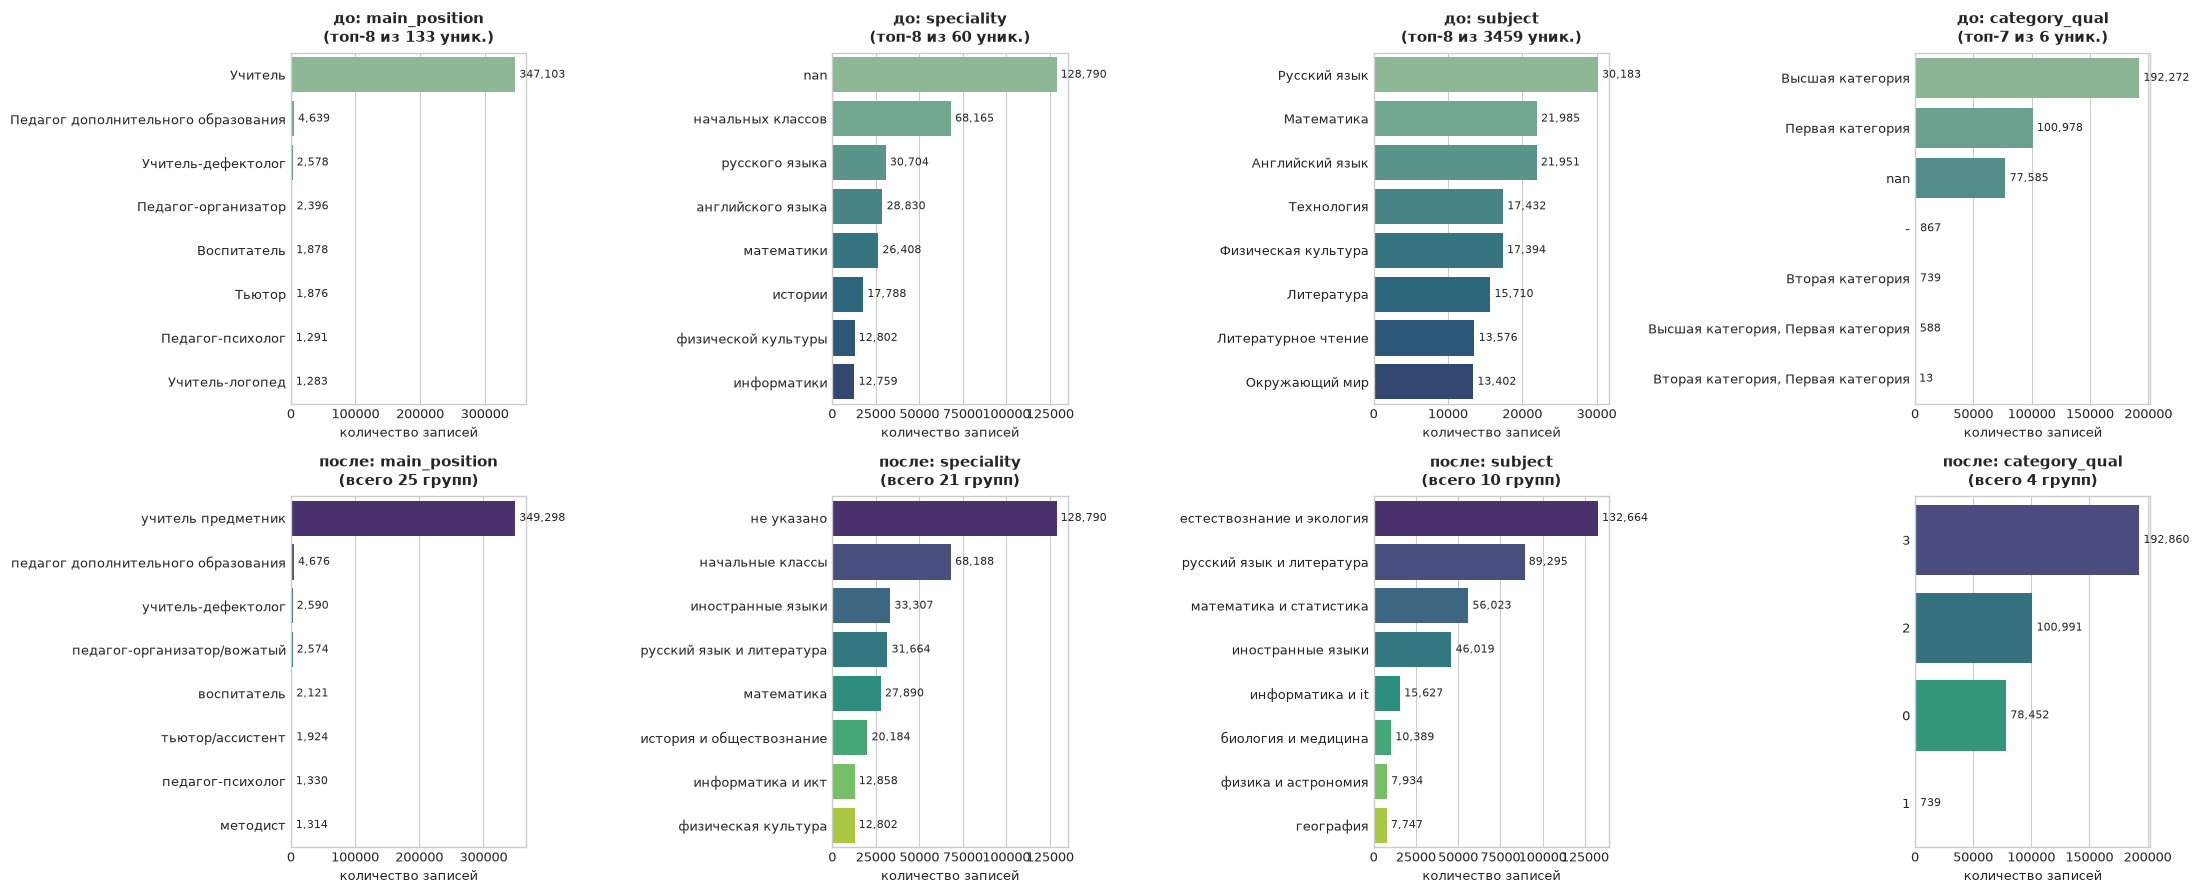

In [12]:
plot_dataset_cleaning_grid(df_before=df_teachers_raw,df_after=df_teachers,columns=['main_position', 'speciality', 'subject', 'category_qual'],top_n=8)

Датасет образования учителей

До обработки:

In [13]:
education_catlist = ['type_education', 'specialization_edu', 'qualification', 'edu_org_name']

for i in education_catlist:
    info_about_feacher_values(df_education, i)

=== type_education (11 уник.) ===
Высшее образование - специалитет, магистратура, Высшее образование, Дополнительное профессиональное образование, Среднее профессиональное образование, Высшее образование - бакалавриат, Среднее (полное) общее образование, Аспирантура, Основное общее образование, Среднее общее образование, Неполное высшее образование, Высшее образование - подготовка кадров высшей квалификации
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
=== specialization_edu (2331 уник.) ===
Теория и методика преподавания иностранных языков и культур, Физика, Математика, Педагогика, Филология, Иностранный язык, Автоматизация и управление, Педагогика и психология, Журналистика, Педагогическое образование, Педагогика и методика начального образования, Преподавание в начальных классах, Информатика, Физическая культура и спорт, Лингвисти

In [14]:
df_education_raw = df_education.copy()

В образовании сворачиваем типы дипломов до уровней высшее, среднее профессиональное, переподготовка и послевузовское. Отдельно выделим подготовку кадров высшей квалификации в послевузовское как сказано в лонге. Сами вузы сворачиваем по профилю, чтобы не плодить сотни редких категорий

Из названий вузов достаем фичу is_capital_univ ставим 1 если вуз московский или питерский, потому что у выпускников столичных институтов выше требования к работе и шире выбор куда уйти

Из квалификации достаем фичу is_pedagogical_qual проверяем есть ли педагогический диплом. Если базового педобразования нет то учителю сложнее адаптироваться к школе и он может уйти в первые годы

In [15]:
# приведение текста к единому виду
education_catlist = ['type_education', 'specialization_edu', 'qualification', 'edu_org_name']
for col in education_catlist:
    df_education[col] = (df_education[col].astype(str).str.lower().str.strip().replace({'nan': np.nan, 'none': np.nan, '': np.nan, '-': np.nan}))

# type_education
def clean_education_type(val):
    if pd.isna(val):
        return 'не указано'
    s = str(val)
    if any(k in s for k in ['аспирант', 'ординат', 'кадров высшей']):
        return 'послевузовское'
    if any(k in s for k in ['высшее', 'бакалавр', 'магистр', 'специалитет']):
        return 'высшее'
    if any(k in s for k in ['среднее профессиональное', 'спо', 'колледж', 'техникум']):
        return 'среднее профессиональное'
    if any(k in s for k in ['дополнительное', 'переподготов', 'повышен', 'дпо']):
        return 'дпо/переподготовка'
    if 'общее' in s:
        return 'среднее общее'
    return 'прочее'

df_education['type_education'] = df_education['type_education'].apply(clean_education_type)

# specialization_edu
def clean_specialization(val):
    if pd.isna(val):
        return 'другая специализация'
    s = str(val)
    if any(k in s for k in ['язык', 'лингвист', 'филолог', 'литератур', 'русск', 'англ', 'иностр']):
        return 'филология и языки'
    if any(k in s for k in ['математ', 'физик', 'алгебр', 'геометр', 'астроном']):
        return 'точная наука (мат/физ)'
    if any(k in s for k in ['информатик', 'программир', 'вычислител', 'автоматизац', 'ит', 'it', 'икт']):
        return 'it и автоматизация'
    if any(k in s for k in ['педагогик', 'начальн', 'дошкольн', 'дефектол', 'логопед']):
        return 'педагогика и воспитание'
    if 'психол' in s:
        return 'психология'
    if any(k in s for k in ['биолог', 'хими', 'естествознан', 'эколог', 'географ']):
        return 'естественные науки'
    if any(k in s for k in ['истор', 'общество', 'прав', 'юриспруд', 'социолог', 'философ']):
        return 'история и социо-гуманитарные'
    if any(k in s for k in ['эконом', 'менеджмент', 'управлен', 'финанс', 'бухгалт']):
        return 'экономика и управление'
    if any(k in s for k in ['физическ', 'спорт', 'культура', 'тренер']):
        return 'спорт и физкультура'
    if any(k in s for k in ['искусств', 'дизайн', 'музык', 'живопис', 'худ']):
        return 'искусство и культура'
    if any(k in s for k in ['технолог', 'инженер', 'машин', 'строител', 'металлург']):
        return 'инженерия и производство'
    return 'другая специализация'

df_education['specialization_edu'] = df_education['specialization_edu'].apply(clean_specialization)

# 4. qualification
def get_is_ped(val): # добавим фичу что работник имеет пед квалификацию
    if pd.isna(val):
        return 0
    s = str(val)
    return 1 if any(k in s for k in ['учитель', 'преподаватель', 'воспитатель', 'педагог']) else 0

def get_qual_role(val):
    if pd.isna(val):
        return 'специалист широкого профиля'
    s = str(val)
    if 'учитель' in s:
        return 'учитель'
    elif 'преподаватель' in s:
        return 'преподаватель'
    elif 'воспитатель' in s:
        return 'воспитатель'
    elif 'педагог' in s:
        return 'педагог'
    elif any(k in s for k in ['лингвист', 'переводчик']):
        return 'лингвист/переводчик'
    elif any(k in s for k in ['инженер', 'техник', 'программист']):
        return 'it'
    elif any(k in s for k in ['бакалавр', 'магистр']):
        return 'академическая степень (бакалавр/магистр)'
    return 'специалист широкого профиля'

df_education['is_pedagogical_qual'] = df_education['qualification'].apply(get_is_ped)
df_education['qualification'] = df_education['qualification'].apply(get_qual_role)

# 5. edu_org_name
def get_is_capital(val): # добавим фичу является ли столичным, столичные и региональные учреждения отличаются
    if pd.isna(val):
        return 0
    s = str(val)
    return 1 if any(city in s for city in ['московск', 'москв', 'спб', 'санкт-петербург', 'ленинград']) else 0

def get_univ_type(val):
    if pd.isna(val):
        return 'прочее учреждение'
    s = str(val)
    if any(k in s for k in ['педагогическ', 'пед.', 'мопи', 'мгпу', 'мпгу']):
        return 'педагогический'
    elif any(k in s for k in ['техническ', 'технологическ', 'стали и сплавов', 'политех', 'бауман', 'мирэа', 'мфти', 'инженер']):
        return 'технический/инженерный'
    elif any(k in s for k in ['медицинск', 'фармацевт']):
        return 'медицинский'
    elif any(k in s for k in ['культуры', 'искусств', 'художественн', 'строганов', 'музык', 'консерватор', 'физической культуры']):
        return 'спорт/искусство'
    elif any(k in s for k in ['колледж', 'техникум', 'училищ']):
        return 'колледж/техникум'
    elif any(k in s for k in ['университет', 'академия', 'институт']):
        return 'университет/институт'
    return 'прочее учреждение'

df_education['is_capital_univ'] = df_education['edu_org_name'].apply(get_is_capital)
df_education['edu_org_name'] = df_education['edu_org_name'].apply(get_univ_type)

После обработки:

In [16]:
for i in education_catlist:
    info_about_feacher_values(df_education, i)

=== type_education (5 уник.) ===
высшее, дпо/переподготовка, среднее профессиональное, среднее общее, послевузовское
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
=== specialization_edu (12 уник.) ===
филология и языки, точная наука (мат/физ), педагогика и воспитание, другая специализация, it и автоматизация, спорт и физкультура, история и социо-гуманитарные, экономика и управление, естественные науки, психология, инженерия и производство, искусство и культура
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
=== qualification (8 уник.) ===
преподаватель, учитель, специалист широкого профиля, it, академическая степень (бакалавр/магистр), педагог, воспитатель, лингвист/переводчик
------

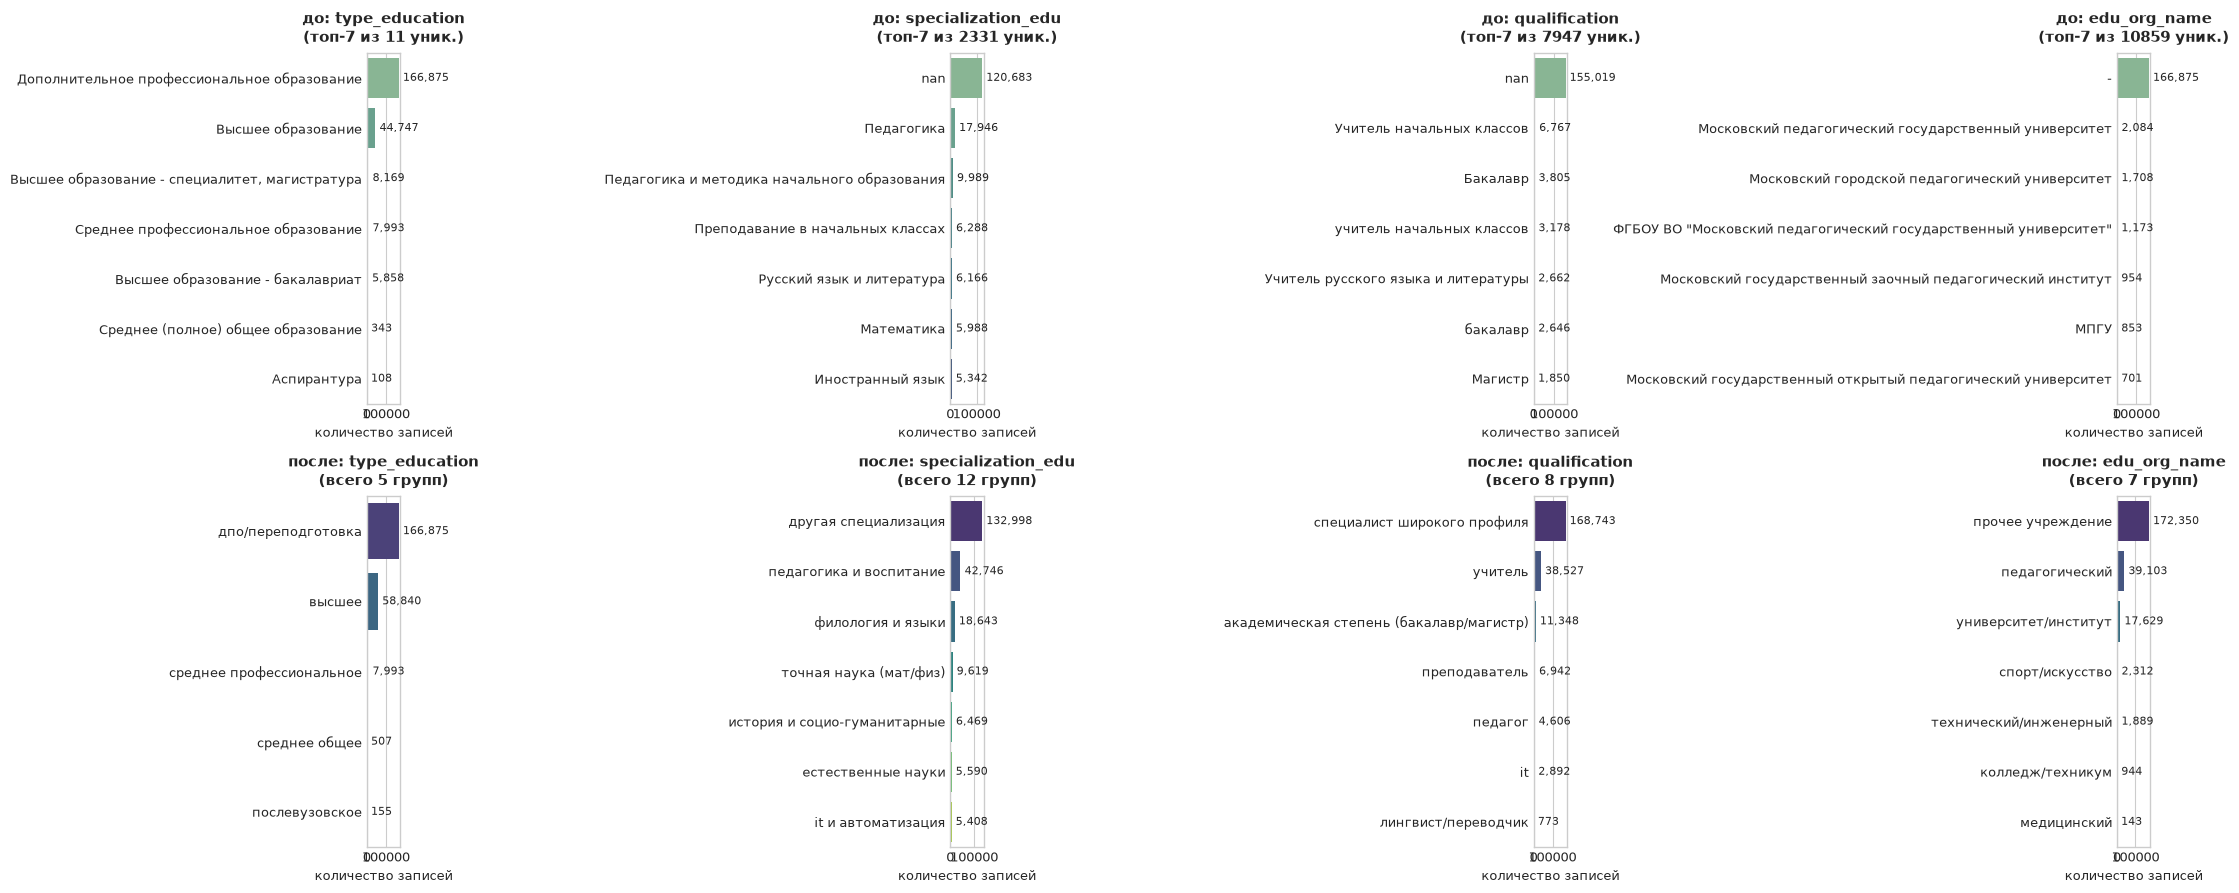

In [17]:
plot_dataset_cleaning_grid(
    df_before=df_education_raw,
    df_after=df_education,
    columns=['type_education', 'specialization_edu', 'qualification', 'edu_org_name'],
    top_n=7
)

Датасет ПК и ПП

До обработки:

In [18]:
pk_pp_catlist = ['name_prog',	'type_prog']

for i in pk_pp_catlist:
    info_about_feacher_values(df_pk_pp, i)

=== name_prog (591 уник.) ===
Методические подходы в подготовке к государственной итоговой аттестации, Организация образовательного процесса в условиях перехода на обновленные ФГОС НОО и ФГОС ООО, Подготовка организаторов пунктов проведения экзаменов при проведении государственной итоговой аттестации по образовательным программам среднего общего образования в городе Москве, Инструменты объективного оценивания уровня достижения образовательных результатов школьников по химии, Подготовка специалистов-экспертов по проведению инструктажа, обеспечению лабораторных работ и оцениванию выполнения лабораторных работ при проведении государственной итоговой аттестации по образовательным программам основного общего образования, Подготовка экспертов для работы в предметной комиссии при проведении государственной итоговой аттестации по образовательным программам среднего общего образования, Подготовка организаторов пунктов проведения экзаменов при проведении государственной итоговой аттестации обуча

In [19]:
df_pk_pp_raw = df_pk_pp.copy()

В этот датасете чистим названия программ и тип обучения. В поле типа разделяем пк и пп, проверяя точные совпадения чтобы одно слово не перебивало другое

Программы делим по темам

In [20]:
pk_pp_catlist = ['name_prog', 'type_prog']

for col in pk_pp_catlist:
    df_pk_pp[col] = (df_pk_pp[col].astype(str).str.lower().str.strip().replace({'nan': np.nan, 'none': np.nan, '': np.nan, '-': np.nan}))

# type_prog кодируем бинарный признак
def clean_type_prog(val):
    if pd.isna(val):
        return np.nan
    s = str(val).lower().strip()
    if s in ['1', '1.0'] or s == 'пк' or 'повышен' in s:
        return 1
    if s in ['0', '0.0'] or s == 'пп' or 'переподготов' in s:
        return 0
    return np.nan

df_pk_pp['type_prog'] = df_pk_pp['type_prog'].apply(clean_type_prog)

# name_prog
def clean_program_name(val):
    if pd.isna(val):
        return 'не указано'
    s = str(val).lower()

    if any(k in s for k in ['гиа', 'егэ', 'огэ', 'ппэ', 'гэк', 'предметной комиссии', 'эксперт', 'итоговой аттестации', 'экзамен']):
        return 'подготовка к гиа/экспертная деятельность'

    if any(k in s for k in ['овз', 'рас', 'аутизм', 'ава-терап', 'интеллектуальн', 'логопед', 'дефектол', 'дислекси', 'тнр', 'зпр', 'адаптирован']):
        return 'инклюзия и работа с овз'

    if any(k in s for k in ['первой помощи', 'безопасност', 'пожарн', 'травматизм', 'антитеррор', 'дорожного движения', 'пдд', 'охране труда']):
        return 'безопасность и первая помощь'

    if any(k in s for k in ['мэш', 'информационн', 'цифров', 'робот', 'python', 'программир', 'алгоритмика', 'искусственн', 'интеллект', 'cad', '3d', 'видеоурок', 'электронн', 'learningapps', 'padlet', 'компас-3d', 'ит-класс', 'ит-полигон']) or bool(re.search(r'\b(it|ит)\b', s)):
        return 'цифровые технологии и мэш'

    if any(k in s for k in ['предпрофессиональн', 'медицинский класс', 'инженерный класс', 'медиакласс', 'лингвистическая вертикаль', 'математическая вертикаль', 'журналистик', 'тележурналистик']):
        return 'предпрофессиональное образование'

    if any(k in s for k in ['классн', 'разговоры о важном', 'воспитани', 'социализац', 'примирен', 'юнармейск', 'кадет', 'наставничеств', 'профилактик']):
        return 'воспитание и классное руководство'

    if any(k in s for k in ['управлен', 'руководител', 'директор', 'менеджмент', 'лидерств', 'маркетинг', 'команд', 'оплаты труда']):
        return 'управление и менеджмент в образовании'

    if any(k in s for k in ['физическ', 'спорт', 'турист', 'поход', 'гто', 'шахмат', 'акварел', 'рисун', 'живопис', 'андрияк', 'музык', 'театр']):
        return 'спорт, искусство и туризм'

    if any(k in s for k in ['фгос', 'грамотност', 'урок', 'методик', 'преподаван', 'сложных тем', 'оцениван', 'содержани', 'практикум', 'предметн']):
        return 'методика предметов и функциональная грамотность'

    return 'прочие программы'

df_pk_pp['name_prog'] = df_pk_pp['name_prog'].apply(clean_program_name)

Поосле обработки:

In [21]:
pk_pp_catlist = ['name_prog',	'type_prog']

for i in pk_pp_catlist:
    info_about_feacher_values(df_pk_pp, i)

=== name_prog (10 уник.) ===
подготовка к гиа/экспертная деятельность, методика предметов и функциональная грамотность, прочие программы, управление и менеджмент в образовании, безопасность и первая помощь, цифровые технологии и мэш, воспитание и классное руководство, спорт, искусство и туризм, инклюзия и работа с овз, предпрофессиональное образование
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
=== type_prog (2 уник.) ===
1, 0
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


/var/folders/6s/mynr1phj1zb0010_r1zg21wh0000gn/T/ipykernel_4656/2663098506.py:70: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


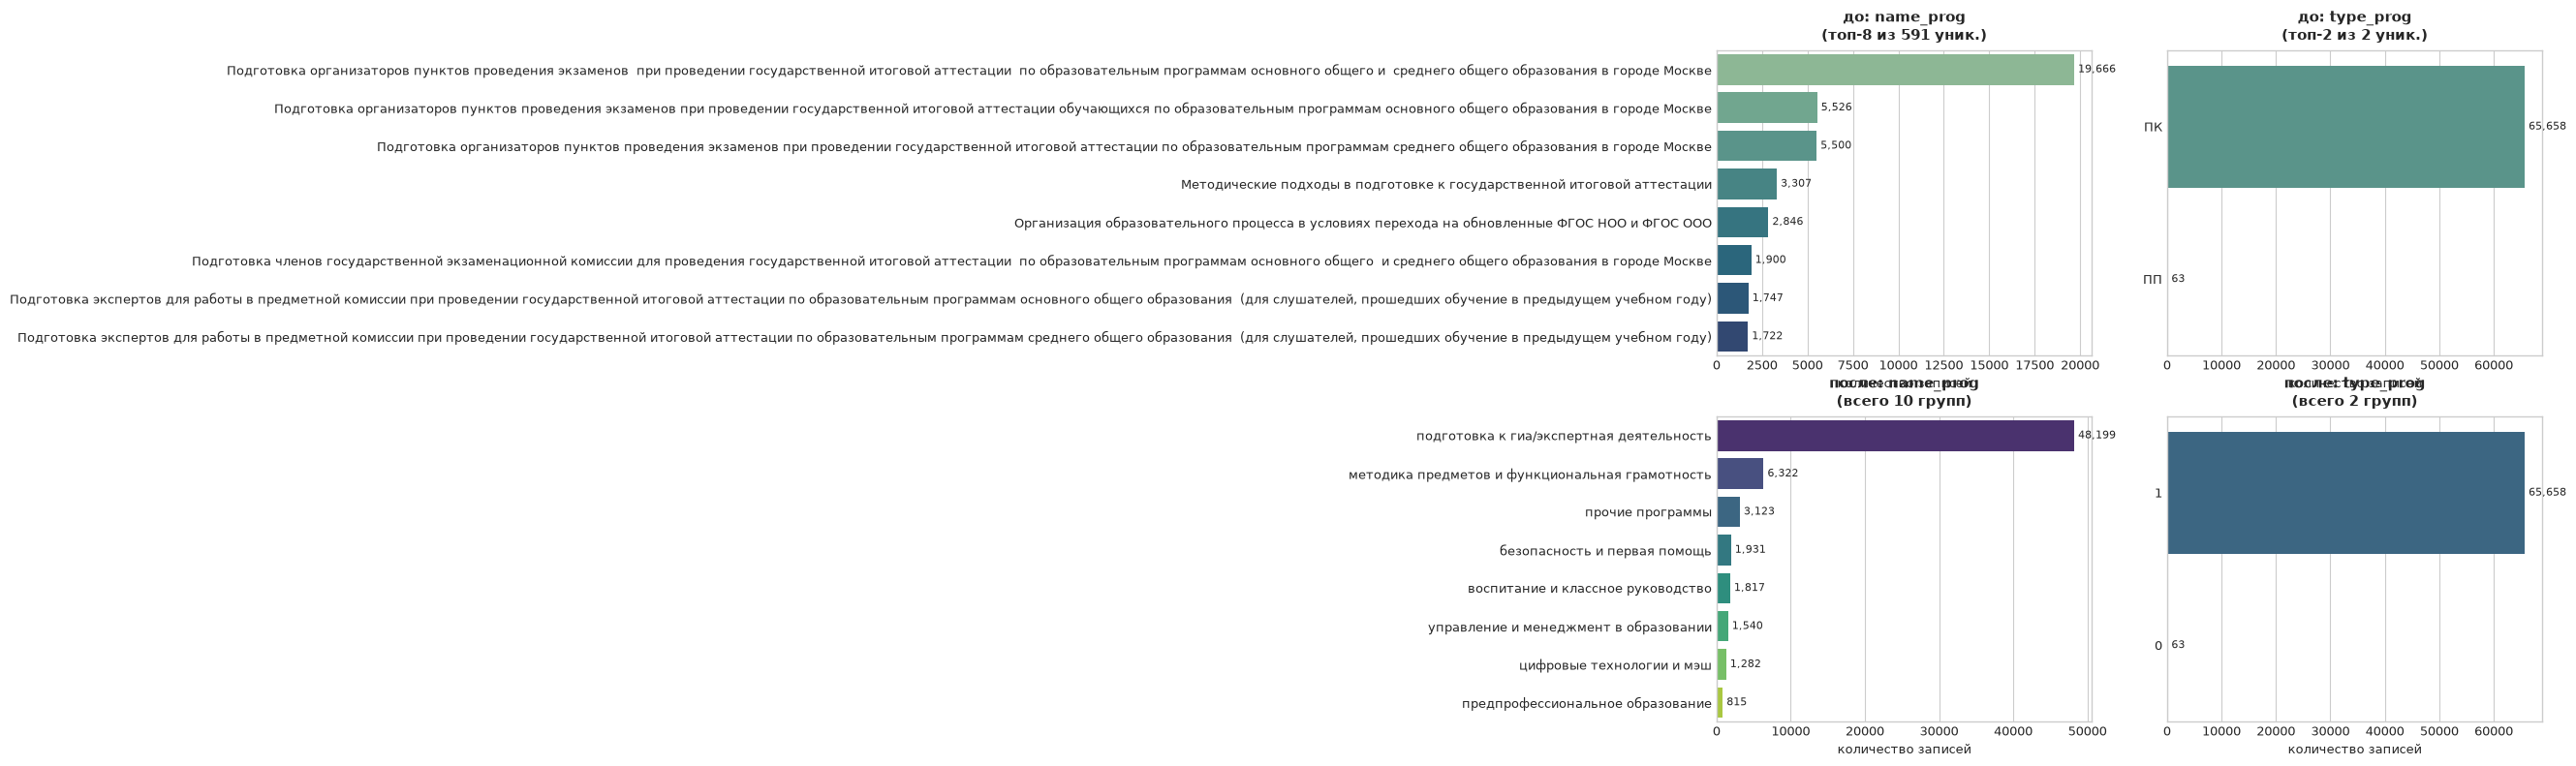

In [22]:
plot_dataset_cleaning_grid(
    df_before=df_pk_pp_raw,
    df_after=df_pk_pp,
    columns=['name_prog', 'type_prog'],
    top_n=8
)

Датасет школ

In [23]:
schools_catlist = ['district']

for i in schools_catlist:
    info_about_feacher_values(df_schools, i)

for col in schools_catlist: # приводим к единому виду
    df_schools[col] = (df_schools[col].astype(str).str.lower().str.strip().replace({'nan': np.nan, 'none': np.nan, '': np.nan, '-': np.nan}))

for i in schools_catlist:
    info_about_feacher_values(df_schools, i)

=== district (5 уник.) ===
Инновационный округ, Северный округ, Западный округ, Восточный округ, Южный округ
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
=== district (5 уник.) ===
инновационный округ, северный округ, западный округ, восточный округ, южный округ
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


Сделаем еще несколько фичей

Выделим фичу is_gia_expert и отмечаем тех кто прошел подготовку экспертов комиссий или организаторов экзаменов. Это показатель статуса и авторитета в школе такие кадры держатся за свое место из-зв статусности

Также добавим is_retirement_age потому что учителя в предпенсионном возрасте или в пенсионном возрасте будут уходить чаще по состоянию здоровья (женщины >58 лет и мужчины >63 лет)

Еще добавим фичу is_early_career из логики: маленький стаж => чаще уходят

In [24]:
target_prog_category = 'подготовка к гиа/экспертная деятельность'

df_pk_pp['is_gia_expert'] = df_pk_pp['name_prog'].apply(lambda x: 1 if pd.notna(x) and str(x).strip() == target_prog_category else 0)

In [25]:
df_teachers['is_early_career'] = (df_teachers['experience_age_pedagogic'] <= 3).astype(int)

In [26]:
def check_retirement_risk(row):
    age = row['age']
    sex = row['sex']
    if pd.isna(age):
        return 0
    if sex == 1 and age >= 58:
        return 1
    if sex == 0 and age >= 63:
        return 1
    return 0

df_teachers['is_retirement_age'] = df_teachers.apply(check_retirement_risk, axis=1)

Агрегация и разметка таргета

Сворачиваем каждую таблицу отдельно до уникальной пары teacher_id и year

По дипломам берем максимальный уровень образования и общее число документов. По курсам считаем суммарное количество учебных часов за год и число пройденных программ

В таблице учителей схлопываем нагрузку и считаем новые фичи subjects_count (сколько разных предметов ведет) и parallels_count (в скольких разных параллелях преподает), также общее число записей нагрузки. Для категорий и флагов берем максимум

После этого собираем все вместе по ключам учителя и года и подтягиваем данные по школе. Если у учителя не было курсов в конкретном году, просто ставим 0 часов и 0 программ

In [27]:
# агрегаци образорвания
#числовой ранг образования по иерархии
edu_rank_dict = {
    'не указано': 0,
    'прочее': 0,
    'среднее общее': 1,
    'дпо/переподготовка': 2,
    'среднее профессиональное': 3,
    'высшее': 4,
    'послевузовское': 5
}
df_education['edu_rank'] = df_education['type_education'].map(edu_rank_dict).fillna(0).astype(int)

# сворачиваем образование
edu_agg = df_education.groupby(['teacher_id', 'year']).agg(
    max_edu_rank=('edu_rank', 'max'),                        # наивысший уровень образования
    has_higher_edu=('edu_rank', lambda x: int((x >= 4).any())), # есть ли высшее иоли послевузовское
    is_pedagogical_qual=('is_pedagogical_qual', 'max'),       # есть ли педагогическая квалификация
    is_capital_univ=('is_capital_univ', 'max'),               # оканчивал ли столичный вуз
    diplomas_count=('type_education', 'count')                # общее число записей об образовании
).reset_index()


# агрегация пк и пп
df_pk_pp['hours_tot_num'] = pd.to_numeric(df_pk_pp['hours_tot'], errors='coerce').fillna(0)

pk_pp_agg = df_pk_pp.groupby(['teacher_id', 'year']).agg(
    pk_courses_count=('name_prog', 'count'),                  # колвоо пройденных программ за год
    pk_hours_total=('hours_tot_num', 'sum'),                  # суммарный объем учебных часов
    is_gia_expert=('is_gia_expert', 'max'),                   # статус эксперта
    has_pp=('type_prog', lambda x: int((x == 0).any()))       # проходил ли пп
).reset_index()



# агрегация нагрущки и учителей


teachers_entity = df_teachers.groupby(['teacher_id', 'year']).agg(
    school_num=('school_num', 'first'),
    sex=('sex', 'first'),
    age=('age', 'first'),
    experience_age_all=('experience_age_all', 'first'),
    experience_age_pedagogic=('experience_age_pedagogic', 'first'),
    academic_degree=('academic_degree', 'first'),

    main_position=('main_position', 'first'),
    speciality=('speciality', 'first'),
    is_main_teacher=('is_main_teacher', 'max'),

    category_qual=('category_qual', 'max'),
    class_manager=('class_manager', 'max'),
    is_high_school_core=('is_high_school_core', 'max'),

    subjects_count=('subject', 'nunique'),       # колво разных преподаваемых предметов
    parallels_count=('parallell', 'nunique'),    # колво параллелей классов
    load_records_count=('subject', 'count')      # общее число строчек нагрузки
).reset_index()


#объединим в однму матрцуи
df_merged = teachers_entity.merge(edu_agg, on=['teacher_id', 'year'], how='left')
df_merged = df_merged.merge(pk_pp_agg, on=['teacher_id', 'year'], how='left')
df_merged = df_merged.merge(df_schools, on='school_num', how='left')

# заполним пропуски учитлей у которых не было курсов в текущем году
df_merged['pk_courses_count'] = df_merged['pk_courses_count'].fillna(0).astype(int)
df_merged['pk_hours_total'] = df_merged['pk_hours_total'].fillna(0)
df_merged['is_gia_expert'] = df_merged['is_gia_expert'].fillna(0).astype(int)
df_merged['has_pp'] = df_merged['has_pp'].fillna(0).astype(int)

# заполним пропуски в образовании
df_merged['max_edu_rank'] = df_merged['max_edu_rank'].fillna(0).astype(int)
df_merged['has_higher_edu'] = df_merged['has_higher_edu'].fillna(0).astype(int)
df_merged['is_pedagogical_qual'] = df_merged['is_pedagogical_qual'].fillna(0).astype(int)
df_merged['is_capital_univ'] = df_merged['is_capital_univ'].fillna(0).astype(int)
df_merged['diplomas_count'] = df_merged['diplomas_count'].fillna(0).astype(int)

Разметка таргета и агрегация

Таргет размечаем по переходам между соседними годами где берем учителей в текущем коду и смотрим, что с ними стало в году следующем

Если учителя в следующем году вообще нет в базе, значит он ушел из системы образования совсем и это 2 класс. Если он остался но у него поменялся номер школы значит это перевод в другую школу это класс 1. Если номер школы остался прежним значит он продолжает работать на своем месте это класс 0

Получаем итоговый датасет где на каждого учителя за конкретный год приходится ровно одна строка со всеми его фичами и известным исходом на следующий период

In [28]:
years = sorted(df_merged['year'].unique())
labeled_parts = []

for i in range(len(years) - 1):
    curr_y = years[i]      #год n
    next_y = years[i + 1]  #год n + 1

    curr_df = df_merged[df_merged['year'] == curr_y].copy()

    next_df = df_merged[df_merged['year'] == next_y][['teacher_id', 'school_num']].copy()
    next_df.rename(columns={'school_num': 'school_num_next'}, inplace=True)

    merged_slice = curr_df.merge(next_df, on='teacher_id', how='left')

    def assign_target(row):
        if pd.isna(row['school_num_next']):
            return 2
        elif row['school_num'] != row['school_num_next']:
            return 1
        else:
            return 0

    merged_slice['target'] = merged_slice.apply(assign_target, axis=1)

    merged_slice.drop(columns=['school_num_next'], inplace=True)
    labeled_parts.append(merged_slice)

df_final = pd.concat(labeled_parts, ignore_index=True)

In [29]:
print("распределение целевой переменной:")
target_names = {
    0: '0 - остался в своей школе',
    1: '1 - перешел в другую школу',
    2: '2 - ушел из сферы образования'
}
print(df_final['target'].map(target_names).value_counts())

распределение целевой переменной:
target
0 - остался в своей школе        28973
2 - ушел из сферы образования     4602
1 - перешел в другую школу        2057
Name: count, dtype: int64


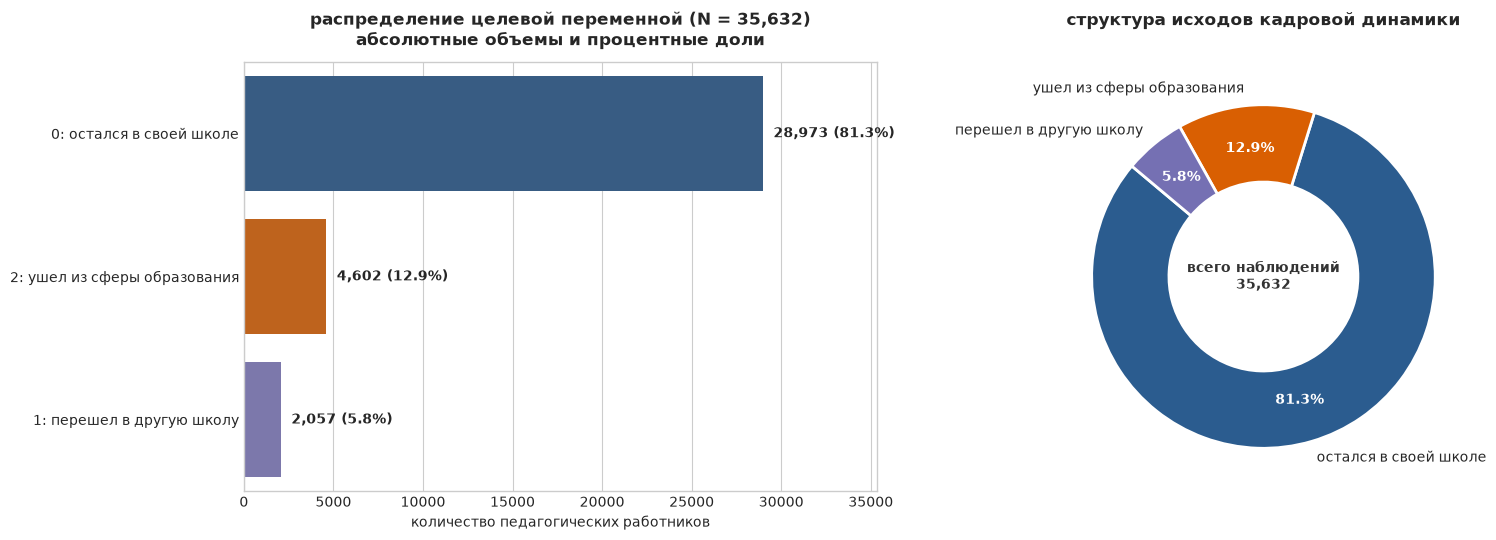

In [30]:
# функция вывода графиков распределеняи таргета

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10

def plot_target_distribution(df, target_col='target'):
    target_names = {
        0: '0: остался в своей школе',
        1: '1: перешел в другую школу',
        2: '2: ушел из сферы образования'
    }

    target_series = df[target_col].map(target_names).fillna(df[target_col].astype(str))
    counts = target_series.value_counts().loc[[
        '0: остался в своей школе',
        '2: ушел из сферы образования',
        '1: перешел в другую школу'
    ]]
    total = len(df)
    percents = (counts / total) * 100

    colors = ['#2b5c8f', '#d95f02', '#7570b3']

    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

    ax_bar = axes[0]
    sns.barplot(
        x=counts.values,
        y=counts.index,
        hue=counts.index,
        legend=False,
        palette=colors,
        ax=ax_bar
    )

    ax_bar.set_title(
        f'распределение целевой переменной (N = {total:,})\nабсолютные объемы и процентные доли',
        fontsize=12, fontweight='bold', pad=12
    )
    ax_bar.set_xlabel('количество педагогических работников', fontsize=10)
    ax_bar.set_ylabel('')

    for p, pct in zip(ax_bar.patches, percents.values):
        w = p.get_width()
        ax_bar.annotate(
            f' {int(w):,} ({pct:.1f}%)',
            (w, p.get_y() + p.get_height() / 2.),
            ha='left', va='center', xytext=(4, 0),
            textcoords='offset points', fontsize=10, fontweight='bold'
        )

    ax_bar.set_xlim(0, max(counts.values) * 1.22)

    ax_pie = axes[1]
    wedges, texts, autotexts = ax_pie.pie(
        counts.values,
        labels=[f"{idx.split(':')[1].strip()}" for idx in counts.index],
        autopct='%1.1f%%',
        pctdistance=0.75,
        startangle=140,
        colors=colors,
        wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
    )

    for t in autotexts:
        t.set_fontsize(10)
        t.set_fontweight('bold')
        t.set_color('white')

    ax_pie.set_title(
        'структура исходов кадровой динамики\n',
        fontsize=12, fontweight='bold', pad=12
    )

    ax_pie.text(
        0, 0, f'всего наблюдений\n{total:,}',
        ha='center', va='center', fontsize=10, fontweight='bold', color='#333333'
    )

    plt.tight_layout()
    plt.show()

plot_target_distribution(df_final, target_col='target')

В данных присутствует сильный дисбаланс классов

In [31]:
display(df_final.head())

display(df_final.info())

display(df_final.describe())

,teacher_id,year,school_num,sex,age,experience_age_all,experience_age_pedagogic,academic_degree,main_position,speciality,...,is_capital_univ,diplomas_count,pk_courses_count,pk_hours_total,is_gia_expert,has_pp,district,buildings_num,students_num,target
0,0000c29d68,2022,121,1,26,5,5,0,учитель предметник,иностранные языки,...,1,4,2,64.0,1,0,южный округ,9.0,1878.0,0
1,000d0f08a6,2022,229,1,49,30,30,0,учитель предметник,не указано,...,1,6,1,16.0,1,0,восточный округ,1.0,1166.0,0
2,000ee8f2b6,2022,442,1,45,27,10,0,учитель предметник,не указано,...,1,4,2,38.0,1,0,южный округ,7.0,2660.0,0
3,00106cc362,2022,269,1,48,30,21,0,учитель предметник,не указано,...,0,4,1,36.0,1,0,восточный округ,15.0,4262.0,0
4,0011288a40,2022,444,1,45,25,17,0,учитель предметник,не указано,...,1,7,2,38.0,1,0,западный округ,4.0,1293.0,0


<class 'pandas.DataFrame'>
RangeIndex: 35632 entries, 0 to 35631
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   teacher_id                35632 non-null  str    
 1   year                      35632 non-null  int64  
 2   school_num                35632 non-null  int64  
 3   sex                       35632 non-null  int64  
 4   age                       35632 non-null  int64  
 5   experience_age_all        35632 non-null  int64  
 6   experience_age_pedagogic  35632 non-null  int64  
 7   academic_degree           35632 non-null  int64  
 8   main_position             35632 non-null  str    
 9   speciality                35632 non-null  str    
 10  is_main_teacher           35632 non-null  int64  
 11  category_qual             35632 non-null  int64  
 12  class_manager             35632 non-null  int64  
 13  is_high_school_core       35632 non-null  int64  
 14  subjects_count   

None

,year,school_num,sex,age,experience_age_all,experience_age_pedagogic,academic_degree,is_main_teacher,category_qual,class_manager,...,is_pedagogical_qual,is_capital_univ,diplomas_count,pk_courses_count,pk_hours_total,is_gia_expert,has_pp,buildings_num,students_num,target
count,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,...,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,35632.000000,34789.000000,34789.000000,35632.000000
mean,2022.499523,269.850500,0.848760,44.255248,22.096627,18.732207,0.022143,0.908593,2.072463,0.639117,...,0.765716,0.514958,4.236220,1.311013,31.010608,0.738016,0.001403,9.158355,2532.360056,0.316036
std,0.500007,147.410867,0.358288,12.826946,13.227020,12.743855,0.147151,0.288191,1.172248,0.480264,...,0.423556,0.499783,2.777849,1.102750,33.920317,0.439720,0.037434,4.739799,988.000280,0.688823
min,2022.000000,0.000000,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,108.000000,0.000000
25%,2022.000000,137.000000,1.000000,33.000000,11.000000,7.000000,0.000000,1.000000,2.000000,0.000000,...,1.000000,0.000000,2.000000,1.000000,16.000000,0.000000,0.000000,6.000000,1878.000000,0.000000
50%,2022.000000,275.000000,1.000000,46.000000,23.000000,18.000000,0.000000,1.000000,3.000000,1.000000,...,1.000000,1.000000,4.000000,1.000000,18.000000,1.000000,0.000000,8.000000,2485.000000,0.000000
75%,2023.000000,403.000000,1.000000,54.000000,33.000000,29.000000,0.000000,1.000000,3.000000,1.000000,...,1.000000,1.000000,6.000000,2.000000,40.000000,1.000000,0.000000,12.000000,3292.000000,0.000000
max,2023.000000,534.000000,1.000000,88.000000,70.000000,67.000000,1.000000,1.000000,3.000000,1.000000,...,1.000000,1.000000,30.000000,13.000000,486.000000,1.000000,1.000000,42.000000,7124.000000,2.000000


# EDA

In [32]:
display(df_final.info())

<class 'pandas.DataFrame'>
RangeIndex: 35632 entries, 0 to 35631
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   teacher_id                35632 non-null  str    
 1   year                      35632 non-null  int64  
 2   school_num                35632 non-null  int64  
 3   sex                       35632 non-null  int64  
 4   age                       35632 non-null  int64  
 5   experience_age_all        35632 non-null  int64  
 6   experience_age_pedagogic  35632 non-null  int64  
 7   academic_degree           35632 non-null  int64  
 8   main_position             35632 non-null  str    
 9   speciality                35632 non-null  str    
 10  is_main_teacher           35632 non-null  int64  
 11  category_qual             35632 non-null  int64  
 12  class_manager             35632 non-null  int64  
 13  is_high_school_core       35632 non-null  int64  
 14  subjects_count   

None

Посмотрим пропуски

In [33]:

miss_final = df_final.isnull().sum()
miss_final = miss_final[miss_final > 0]
pct_final = (miss_final / len(df_final) * 100).round(2)

df_miss_final = pd.DataFrame({'Пропусков шт': miss_final, '%': pct_final})
display(df_miss_final)

,Пропусков шт,%
district,843,2.37
buildings_num,843,2.37
students_num,843,2.37


Посмотрим распределения фичей с пропусками

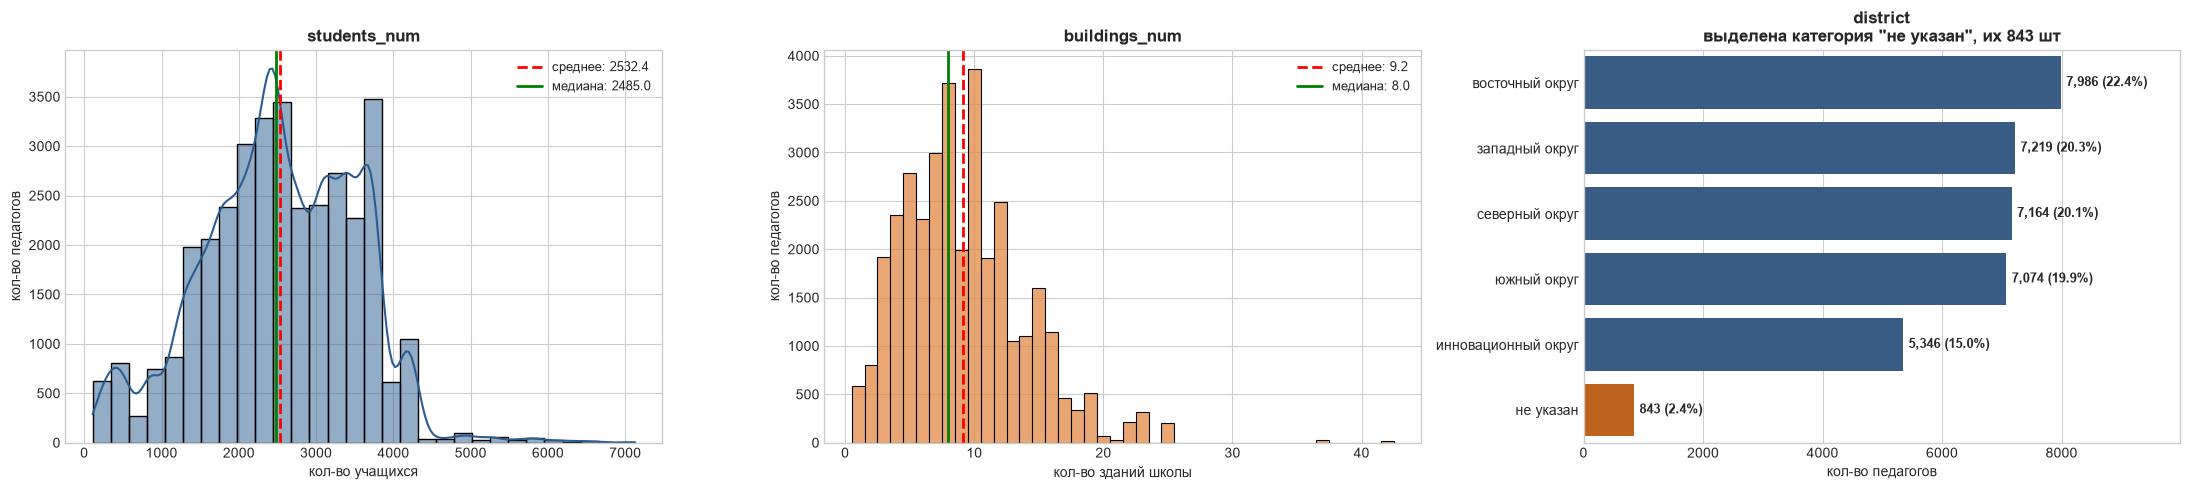

In [34]:
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 3, figsize=(22, 5))

mean_stud = df_final['students_num'].mean()
median_stud = df_final['students_num'].median()

sns.histplot(df_final['students_num'].dropna(), kde=True, ax=axes[0], color='#2b5c8f', bins=30)
axes[0].axvline(mean_stud, color='red', linestyle='--', linewidth=2, label=f'среднее: {mean_stud:.1f}')
axes[0].axvline(median_stud, color='green', linestyle='-', linewidth=2, label=f'медиана: {median_stud:.1f}')
axes[0].set_title('students_num', fontsize=12, fontweight='bold')
axes[0].set_xlabel('кол-во учащихся', fontsize=10)
axes[0].set_ylabel('кол-во педагогов', fontsize=10)
axes[0].legend(fontsize=9)

mean_bld = df_final['buildings_num'].mean()
median_bld = df_final['buildings_num'].median()
skew_bld = df_final['buildings_num'].skew()

sns.histplot(df_final['buildings_num'].dropna(), discrete=True, ax=axes[1], color='#e28743')
axes[1].axvline(mean_bld, color='red', linestyle='--', linewidth=2, label=f'среднее: {mean_bld:.1f}')
axes[1].axvline(median_bld, color='green', linestyle='-', linewidth=2, label=f'медиана: {median_bld:.1f}')
axes[1].set_title('buildings_num', fontsize=12, fontweight='bold')
axes[1].set_xlabel('кол-во зданий школы', fontsize=10)
axes[1].set_ylabel('кол-во педагогов', fontsize=10)
axes[1].legend(fontsize=9)

district_counts = df_final['district'].fillna('не указан').value_counts()
colors = ['#2b5c8f' if idx != 'не указан' else '#d95f02' for idx in district_counts.index]

sns.barplot(
    x=district_counts.values,
    y=district_counts.index,
    palette=colors,
    ax=axes[2]
)
axes[2].set_title('district\nвыделена категория "не указан", их 843 шт', fontsize=12, fontweight='bold')
axes[2].set_xlabel('кол-во педагогов', fontsize=10)
axes[2].set_ylabel('')

total_records = len(df_final)
for p in axes[2].patches:
    w = p.get_width()
    pct = (w / total_records) * 100
    axes[2].annotate(f'{int(w):,} ({pct:.1f}%)', 
                     (w, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', xytext=(4, 0), 
                     textcoords='offset points', fontsize=9, fontweight='bold')

axes[2].set_xlim(0, max(district_counts.values) * 1.25)

plt.tight_layout()
plt.show()

In [35]:
df_final['district'] = df_final['district'].fillna('не указан')
df_final['buildings_num'] = df_final['buildings_num'].fillna(df_final['buildings_num'].median())
df_final['students_num'] = df_final['students_num'].fillna(df_final['students_num'].median())

В результате анализа формы распределений признаков с пропусками:

students_num и buildings_num заполнили медианой, тк на графиках распределения есть большие хвосты справа и в такой ситуации брать среднее нельзя оно смещённое, поэтому взял медиану тк она не реагирует на эти единичные аномалии

district заполнили как "не указан", чтобы не размывать статистику по нормальным округам и не придумывать за школу район, просто выделил это в отдельную категорию

In [36]:
print("осталось пропусков:", df_final.isnull().sum().sum())

осталось пропусков: 0


Детекция и обработка выбросов

численные фичи для анализа выбросов:
['age', 'experience_age_all', 'experience_age_pedagogic', 'category_qual', 'subjects_count', 'parallels_count', 'load_records_count', 'max_edu_rank', 'diplomas_count', 'pk_courses_count', 'pk_hours_total', 'buildings_num', 'students_num']


,фича,мин,Q1 (25%),медиана,среднее,Q3 (75%),макс,нижн. гран. IQR,верхн. гран. IQR,99 перц.,выбросов шт,%
0,age,17.0,33.0,46.0,44.3,54.0,88.0,1.5,85.5,70.0,2,0.01
1,experience_age_all,0.0,11.0,23.0,22.1,33.0,70.0,-22.0,66.0,49.0,3,0.01
2,experience_age_pedagogic,0.0,7.0,18.0,18.7,29.0,67.0,-26.0,62.0,47.0,3,0.01
3,category_qual,0.0,2.0,3.0,2.1,3.0,3.0,0.5,4.5,3.0,7736,21.71
4,subjects_count,1.0,1.0,1.0,1.8,3.0,7.0,-2.0,6.0,4.0,5,0.01
5,parallels_count,1.0,1.0,3.0,3.3,5.0,11.0,-5.0,11.0,8.0,0,0.00
6,load_records_count,1.0,5.0,7.0,6.9,9.0,57.0,-1.0,15.0,16.0,444,1.25
7,max_edu_rank,0.0,4.0,4.0,3.9,4.0,5.0,4.0,4.0,4.0,1867,5.24
8,diplomas_count,0.0,2.0,4.0,4.2,6.0,30.0,-4.0,12.0,13.0,376,1.06
9,pk_courses_count,0.0,1.0,1.0,1.3,2.0,13.0,-0.5,3.5,5.0,1492,4.19


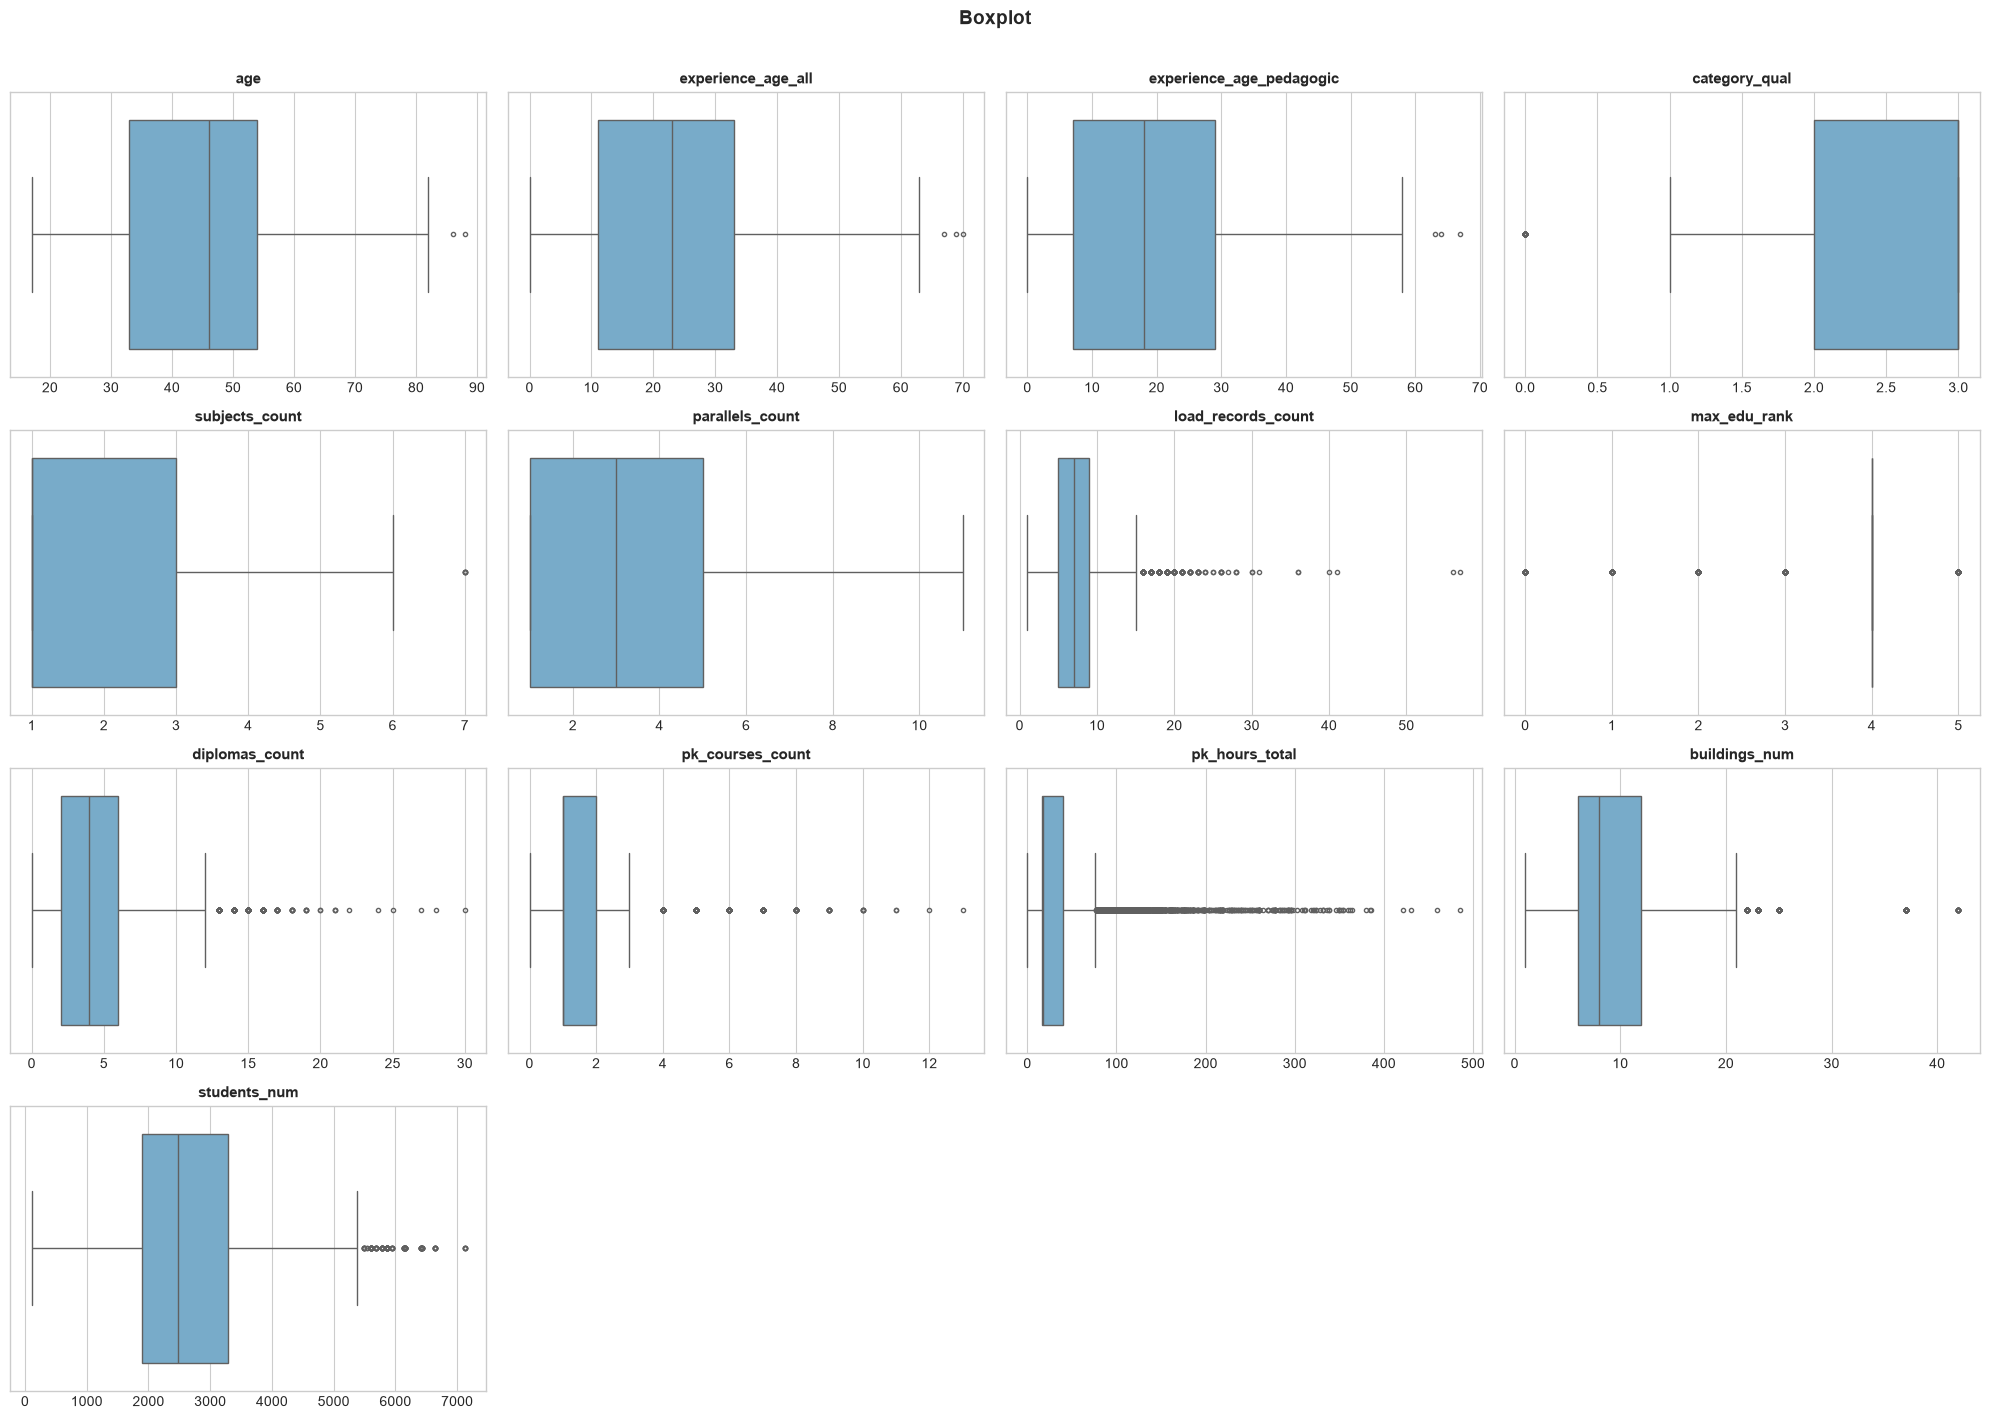

In [37]:
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

num_candidates = df_final.select_dtypes(include=['int64', 'float64']).columns.tolist()

exclude_cols = ['year', 'school_num', 'target']

numeric_features = [
    col for col in num_candidates 
    if col not in exclude_cols and df_final[col].nunique() > 2
]

print("численные фичи для анализа выбросов:")
print(numeric_features)

def get_iqr_stats(df, col):
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    p99 = s.quantile(0.99)
    outliers = s[(s < lower_bound) | (s > upper_bound)]
    
    return {
        'фича': col,
        'мин': round(s.min(), 1),
        'Q1 (25%)': round(q1, 1),
        'медиана': round(s.median(), 1),
        'среднее': round(s.mean(), 1),
        'Q3 (75%)': round(q3, 1),
        'макс': round(s.max(), 1),
        'нижн. гран. IQR': round(lower_bound, 1),
        'верхн. гран. IQR': round(upper_bound, 1),
        '99 перц.': round(p99, 1),
        'выбросов шт': len(outliers),
        '%': round(len(outliers) / len(s) * 100, 2)
    }

df_iqr_report = pd.DataFrame([get_iqr_stats(df_final, col) for col in numeric_features])
display(df_iqr_report)

n_cols = 4
n_rows = int(np.ceil(len(numeric_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3.5 * n_rows))
axes = axes.flatten()

for idx, col in enumerate(numeric_features):
    sns.boxplot(x=df_final[col], ax=axes[idx], color='#6baed6', fliersize=3)
    axes[idx].set_title(col, fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('')

for j in range(len(numeric_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Boxplot', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

Обработка выбросов

В фичах age, experience_age_all, experience_age_pedagogic выбросов всего по 2-3 человека. Максимальный возраст 88 лет и стаж до 67 лет это реальные работающие педагоги. Ошибок ввода здесь нет поэтому трогать и удалять их не будем

load_records_count, pk_hours_total, diplomas_count - у этих признаков длинный правый хвост, есть учителя с 50+ строками нагрузки в расписании или почти 500 часами курсов за год. Для них применим винсоризацию на 99 перцентиля, это прижимет единичные экстремальные значения к границе и уберет искажение масштаба

buildings_num и students_num. Несколько больших школ улетают далеко за усы. Будем клипировать их по верхней границе IQR, чтобы гигантские школы не смещали оценки моделей

In [38]:
df_final_clean = df_final.copy()

winsor_features = ['load_records_count', 'pk_hours_total', 'diplomas_count']

for col in winsor_features:
    cap_value = df_final_clean[col].quantile(0.99)
    df_final_clean[col] = np.where(df_final_clean[col] > cap_value, cap_value, df_final_clean[col])

df_final_clean['buildings_num'] = df_final_clean['buildings_num'].clip(upper=21.0)
df_final_clean['students_num'] = df_final_clean['students_num'].clip(upper=5392.0)

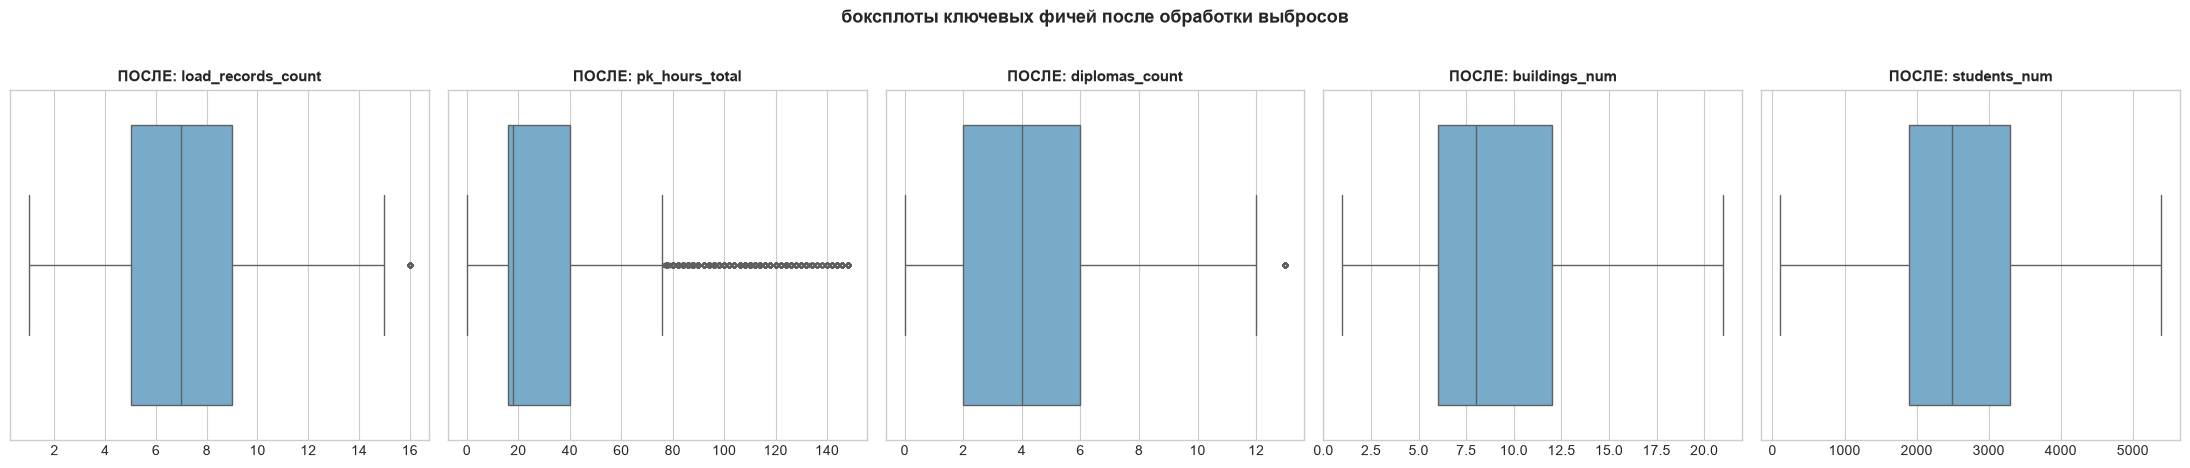

In [39]:
treated_cols = ['load_records_count', 'pk_hours_total', 'diplomas_count', 'buildings_num', 'students_num']

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))

for idx, col in enumerate(treated_cols):
    sns.boxplot(x=df_final_clean[col], ax=axes[idx], color='#6baed6', fliersize=3)
    axes[idx].set_title(f'ПОСЛЕ: {col}', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('')

plt.suptitle('боксплоты ключевых фичей после обработки выбросов', 
             fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

Корреляционный анализ 

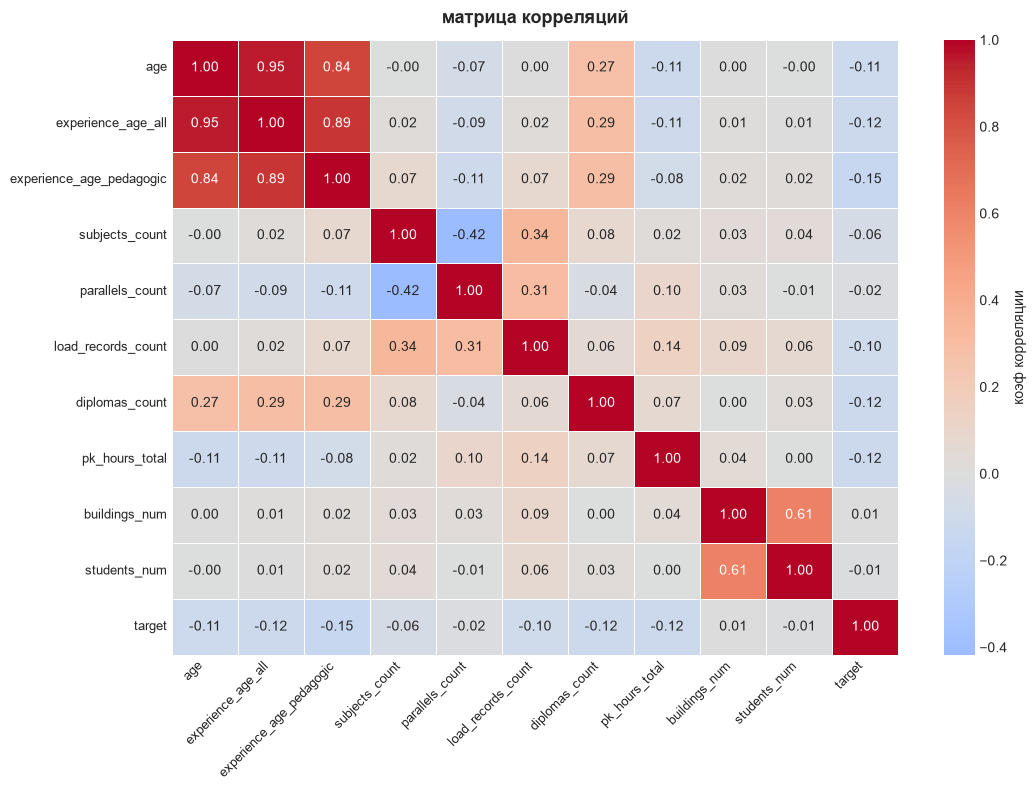

In [40]:
corr_cols = [
    'age', 'experience_age_all', 'experience_age_pedagogic',
    'subjects_count', 'parallels_count', 'load_records_count',
    'diplomas_count', 'pk_hours_total', 'buildings_num', 'students_num',
    'target'
] # отобрали фичи с непрерывными величинами

corr_matrix = df_final_clean[corr_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    center=0, 
    linewidths=0.5,
    cbar_kws={'label': 'коэф корреляции'}
)

plt.title('матрица корреляций', fontsize=13, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

Возраст и стаж дублируют друг друга с большой корреляцией, что означает учителя редко уходят из профессии, для линейных моделей в будущем оставим только стаж чтобы веса модели оставались смтабильными

Количество предметов и параллелей показало обратную связь и это логично, тк учителя началки ведут кучу разных предметов внутри одного двух классов, а предметники наоборот берут одну дисциплину но тянут ее через все параллели с 5 по 11

Линейная связь всех параметров с самим уходом учителей околонулевая. Это важно, тк это буквально ознанчает что увольнения зависят от сложных нелинейных связок факторов, поэтому это намек на более сложные ансамблевые методы решения

In [ ]:
df_final_clean.to_csv('dataset.csv', index=False)